Dementia Prediction: Comparing 6 Machine Learning Models

Project Overview
Dementia is a progressive neurological condition affecting over 55 million people worldwide. Early detection is critical for intervention and disease management. This project develops machine learning models to predict dementia diagnosis using clinical assessments, demographic data, and health indicators.
Dataset Source: Kaggle - Dementia Patient Health Dataset

Project Goals

Build binary classification models to predict dementia (Yes/No)
Compare performance across 6 machine learning algorithms
Identify most important predictive features
Achieve high recall (sensitivity) to minimize false negatives



## 1. Data Understanding  
### 1.1 Import Libraries and Load Data

In [5]:
# Data manipulation
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from sklearn.feature_selection import SelectKBest, chi2, f_classif

from scipy.stats import chi2_contingency, pointbiserialr
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

# Import dataset
df = pd.read_csv('/Users/chenqi/Desktop/healthinfo./12025fall/DSC445/project/dementia_patients_health_data.csv')
df_org = df.copy()  # Keep original copy


### 1.2 Data Overview 


In [7]:
## Basic Overview Check data types and missing values
print(df.info())
print("\n" + "="*50)
print("Target Variable Distribution:")
print(df['Dementia'].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 24 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Diabetic                   1000 non-null   int64  
 1   AlcoholLevel               1000 non-null   float64
 2   HeartRate                  1000 non-null   int64  
 3   BloodOxygenLevel           1000 non-null   float64
 4   BodyTemperature            1000 non-null   float64
 5   Weight                     1000 non-null   float64
 6   MRI_Delay                  1000 non-null   float64
 7   Prescription               485 non-null    object 
 8   Dosage in mg               485 non-null    float64
 9   Age                        1000 non-null   int64  
 10  Education_Level            1000 non-null   object 
 11  Dominant_Hand              1000 non-null   object 
 12  Gender                     1000 non-null   object 
 13  Family_History             1000 non-null   object

### 1.3 Identify Feature Types
‘Dementia’ and ‘Diabetic’ were coded as 0/1 integers, so they were converted to categorical variables to ensure correct handling in the models.

In [9]:
# Convert selected 'Dementia', 'Diabetic' columns to category
binary_cols = ['Dementia', 'Diabetic']
for col in binary_cols:
    df[col] = df[col].astype('category')
df[binary_cols].describe().T
df[binary_cols].dtypes


Dementia    category
Diabetic    category
dtype: object

In [10]:
# Numerical features
numeric_features = df.select_dtypes(include=[np.number])
print("Numerical Features:")
print(numeric_features.columns.tolist())

# Categorical features
categorical_features = df.select_dtypes(include=['object', 'category'])
print("\nCategorical Features:")
print(categorical_features.columns.tolist())

Numerical Features:
['AlcoholLevel', 'HeartRate', 'BloodOxygenLevel', 'BodyTemperature', 'Weight', 'MRI_Delay', 'Dosage in mg', 'Age', 'Cognitive_Test_Scores']

Categorical Features:
['Diabetic', 'Prescription', 'Education_Level', 'Dominant_Hand', 'Gender', 'Family_History', 'Smoking_Status', 'APOE_ε4', 'Physical_Activity', 'Depression_Status', 'Medication_History', 'Nutrition_Diet', 'Sleep_Quality', 'Chronic_Health_Conditions', 'Dementia']


### 1.4 Descriptive Statistics

In [12]:
# Understanding Categorical features
for col in categorical_features:
    print(f"\n=== {col} ===")
    display(pd.DataFrame({
        "Count": df[col].value_counts(dropna=False),
        "Proportion": df[col].value_counts(normalize=True)
    }))



=== Diabetic ===


,Count,Proportion
Diabetic,,
1,513,0.513
0,487,0.487



=== Prescription ===


,Count,Proportion
Prescription,,
Donepezil,113,0.232990
Galantamine,125,0.257732
Memantine,128,0.263918
Rivastigmine,119,0.245361
NaN,515,NaN



=== Education_Level ===


...

,Count,Proportion
Sleep_Quality,,
Poor,534,0.534
Good,466,0.466



=== Chronic_Health_Conditions ===


,Count,Proportion
Chronic_Health_Conditions,,
Diabetes,513,0.624848
Heart Disease,155,0.188794
Hypertension,153,0.186358
NaN,179,NaN



=== Dementia ===


,Count,Proportion
Dementia,,
0,515,0.515
1,485,0.485


/var/folders/d1/fzn8x7ss3597j38z1g8kc8wm0000gn/T/ipykernel_59556/4000791780.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=feature, ax=axes[i], palette='Set2')
/var/folders/d1/fzn8x7ss3597j38z1g8kc8wm0000gn/T/ipykernel_59556/4000791780.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=feature, ax=axes[i], palette='Set2')
/var/folders/d1/fzn8x7ss3597j38z1g8kc8wm0000gn/T/ipykernel_59556/4000791780.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=feature, ax=axes[i], palette='Set2')
/var/folders/

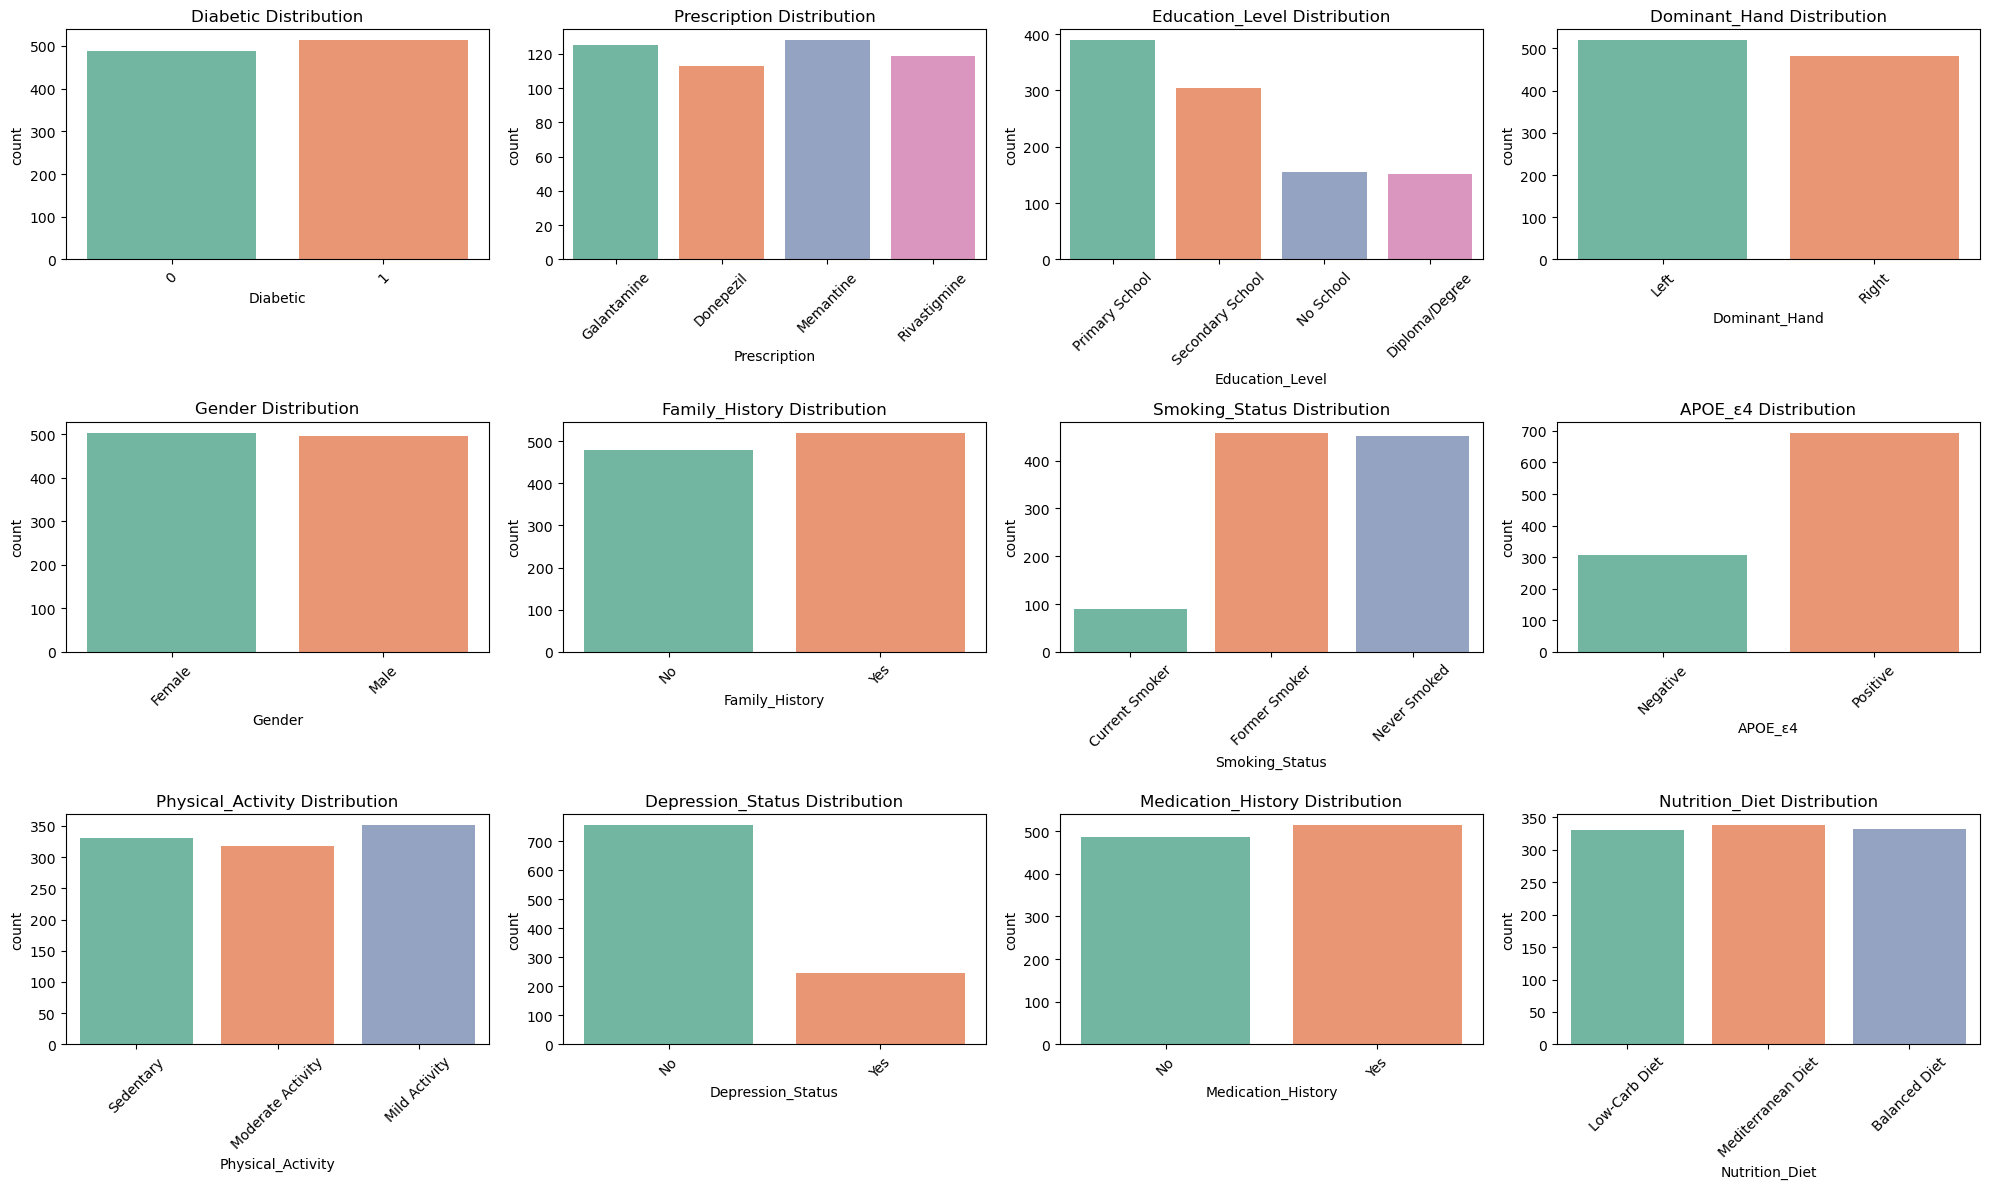

In [13]:
# Visualize all categorical features
def plot_categorical_features(df, categorical_cols, rows=3, cols=4):
    fig, axes = plt.subplots(rows, cols, figsize=(20, 12))
    axes = axes.flatten()
    
    for i, feature in enumerate(categorical_cols):
        if i < len(axes):
            sns.countplot(data=df, x=feature, ax=axes[i], palette='Set2')
            axes[i].set_title(f'{feature} Distribution')
            axes[i].tick_params(axis='x', rotation=45)
    
    # Remove extra subplots
    for j in range(i+1, len(axes)):
        fig.delaxes(axes[j])
    
    plt.tight_layout()
    plt.show()

# Get categorical columns (exclude target)
cat_cols = [col for col in categorical_features.columns if col != 'Dementia']
plot_categorical_features(df, cat_cols)

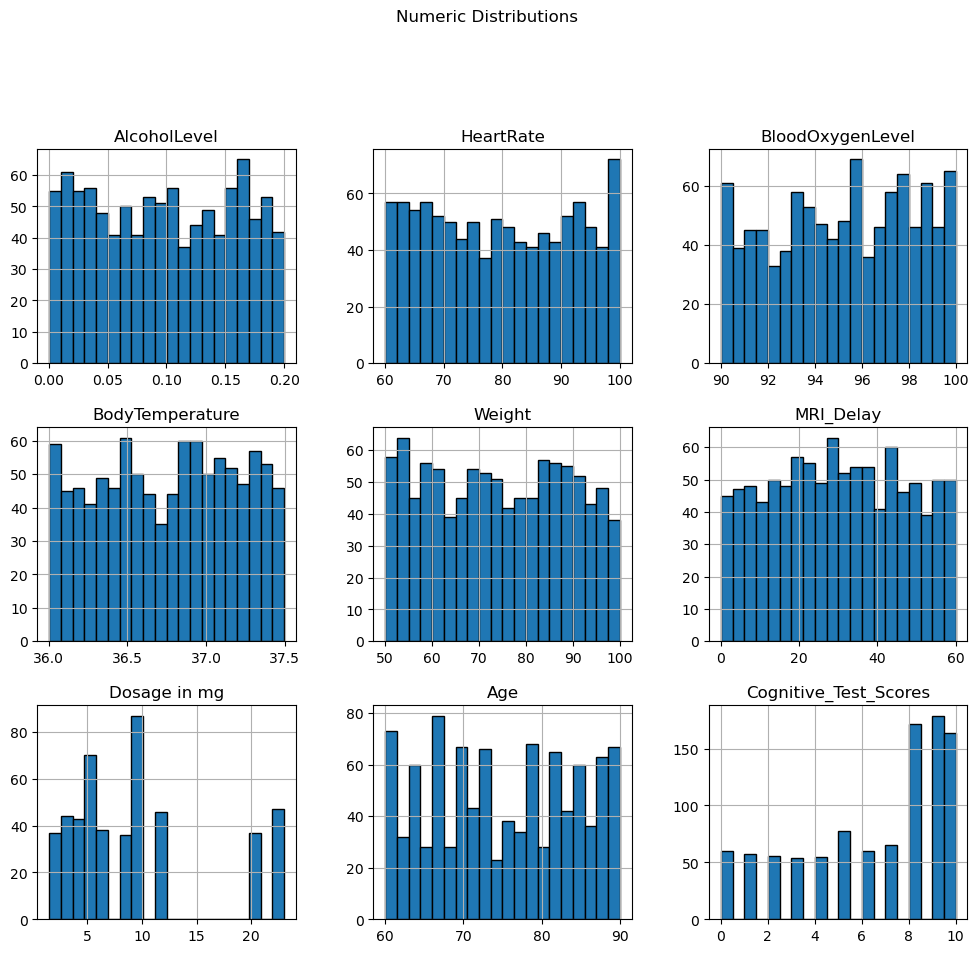

In [14]:

# Numeric Distribution
df.hist(figsize=(12, 10), bins=20, edgecolor="black")
plt.suptitle("Numeric Distributions", y=1.02)
plt.show()

In [15]:
# Generate descriptive statistics for numerical features
df.describe().T.style.background_gradient(cmap='Blues')

,count,mean,std,min,25%,50%,75%,max
AlcoholLevel,1000.000000,0.098429,0.058715,0.000414,0.045505,0.098235,0.151840,0.199866
HeartRate,1000.000000,79.383000,12.107556,60.000000,68.000000,79.000000,90.000000,100.000000
BloodOxygenLevel,1000.000000,95.226051,2.929262,90.010677,92.875017,95.390420,97.785111,99.999230
BodyTemperature,1000.000000,36.761513,0.431701,36.002108,36.395363,36.784319,37.126655,37.496809
Weight,1000.000000,74.321326,14.463765,50.069731,61.387339,74.149204,87.024034,99.982722
MRI_Delay,1000.000000,30.103568,16.862170,0.094684,16.237371,29.577194,44.176723,59.957599
Dosage in mg,485.000000,9.213402,6.493188,1.500000,4.000000,8.000000,12.000000,23.000000
Age,1000.000000,74.908000,9.095068,60.000000,67.000000,75.000000,83.000000,90.000000
Cognitive_Test_Scores,1000.000000,6.383000,3.180633,0.000000,4.000000,8.000000,9.000000,10.000000


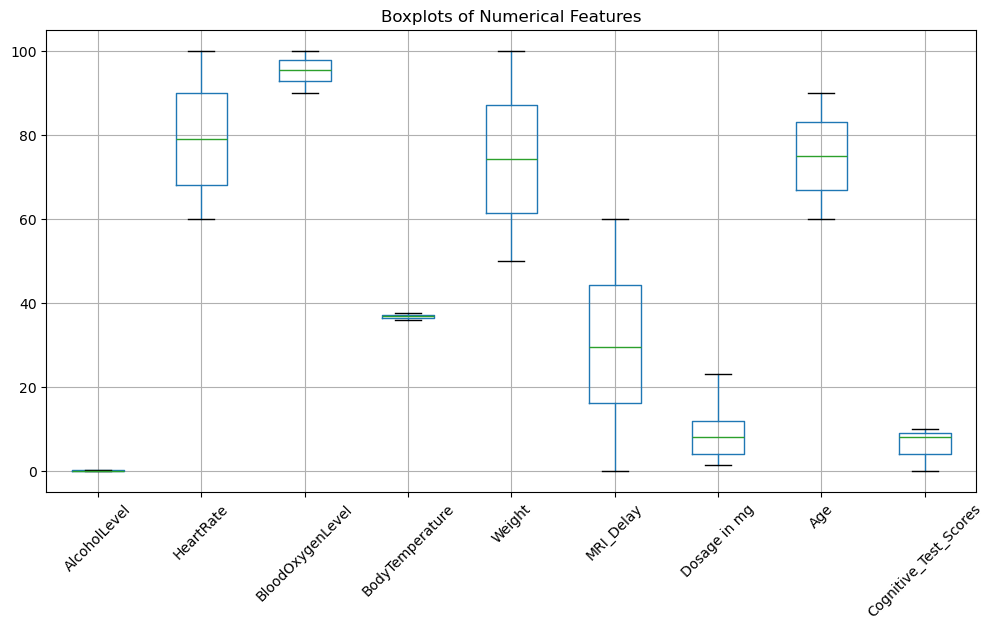


Outlier count per feature:
AlcoholLevel: 0
HeartRate: 0
BloodOxygenLevel: 0
BodyTemperature: 0
Weight: 0
MRI_Delay: 0
Dosage in mg: 0
Age: 0
Cognitive_Test_Scores: 0


In [16]:
# Understanding Numeric features

numeric_cols = df.select_dtypes(include=[np.number]).columns

plt.figure(figsize=(12, 6))
df[numeric_cols].boxplot(rot=45)
plt.title("Boxplots of Numerical Features")
plt.show()

# Optional: IQR outlier flagging (not removing automatically)
def detect_outliers(col):
    Q1, Q3 = col.quantile([0.25, 0.75])
    IQR = Q3 - Q1
    return ((col < Q1 - 1.5*IQR) | (col > Q3 + 1.5*IQR)).sum()

print("\nOutlier count per feature:")
for col in numeric_cols:
    print(f"{col}: {detect_outliers(df[col])}")


## 2. Exploratory Data Analysis  
### 2.1 Target Variable Distribution

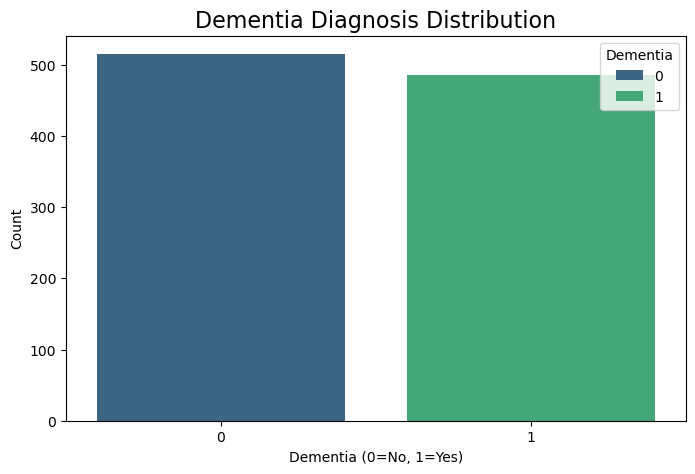

Class Distribution:
No Dementia: 515 (51.5%)
Dementia: 485 (48.5%)
Imbalance Ratio: 1.06:1


In [18]:
# Visualize dementia diagnosis distribution
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Dementia',hue='Dementia', palette='viridis')
plt.title('Dementia Diagnosis Distribution', fontsize=16)
plt.xlabel('Dementia (0=No, 1=Yes)')
plt.ylabel('Count')
plt.show()

# Calculate class imbalance ratio
dementia_counts = df['Dementia'].value_counts()
print(f"Class Distribution:")
print(f"No Dementia: {dementia_counts[0]} ({dementia_counts[0]/len(df)*100:.1f}%)")
print(f"Dementia: {dementia_counts[1]} ({dementia_counts[1]/len(df)*100:.1f}%)")
print(f"Imbalance Ratio: {dementia_counts[0]/dementia_counts[1]:.2f}:1")


4.2 Univariate Analysis - Categorical Features


4.3 Univariate Analysis - Numerical Features

### 2.2 Bivariate Analysis - Categorical vs Target

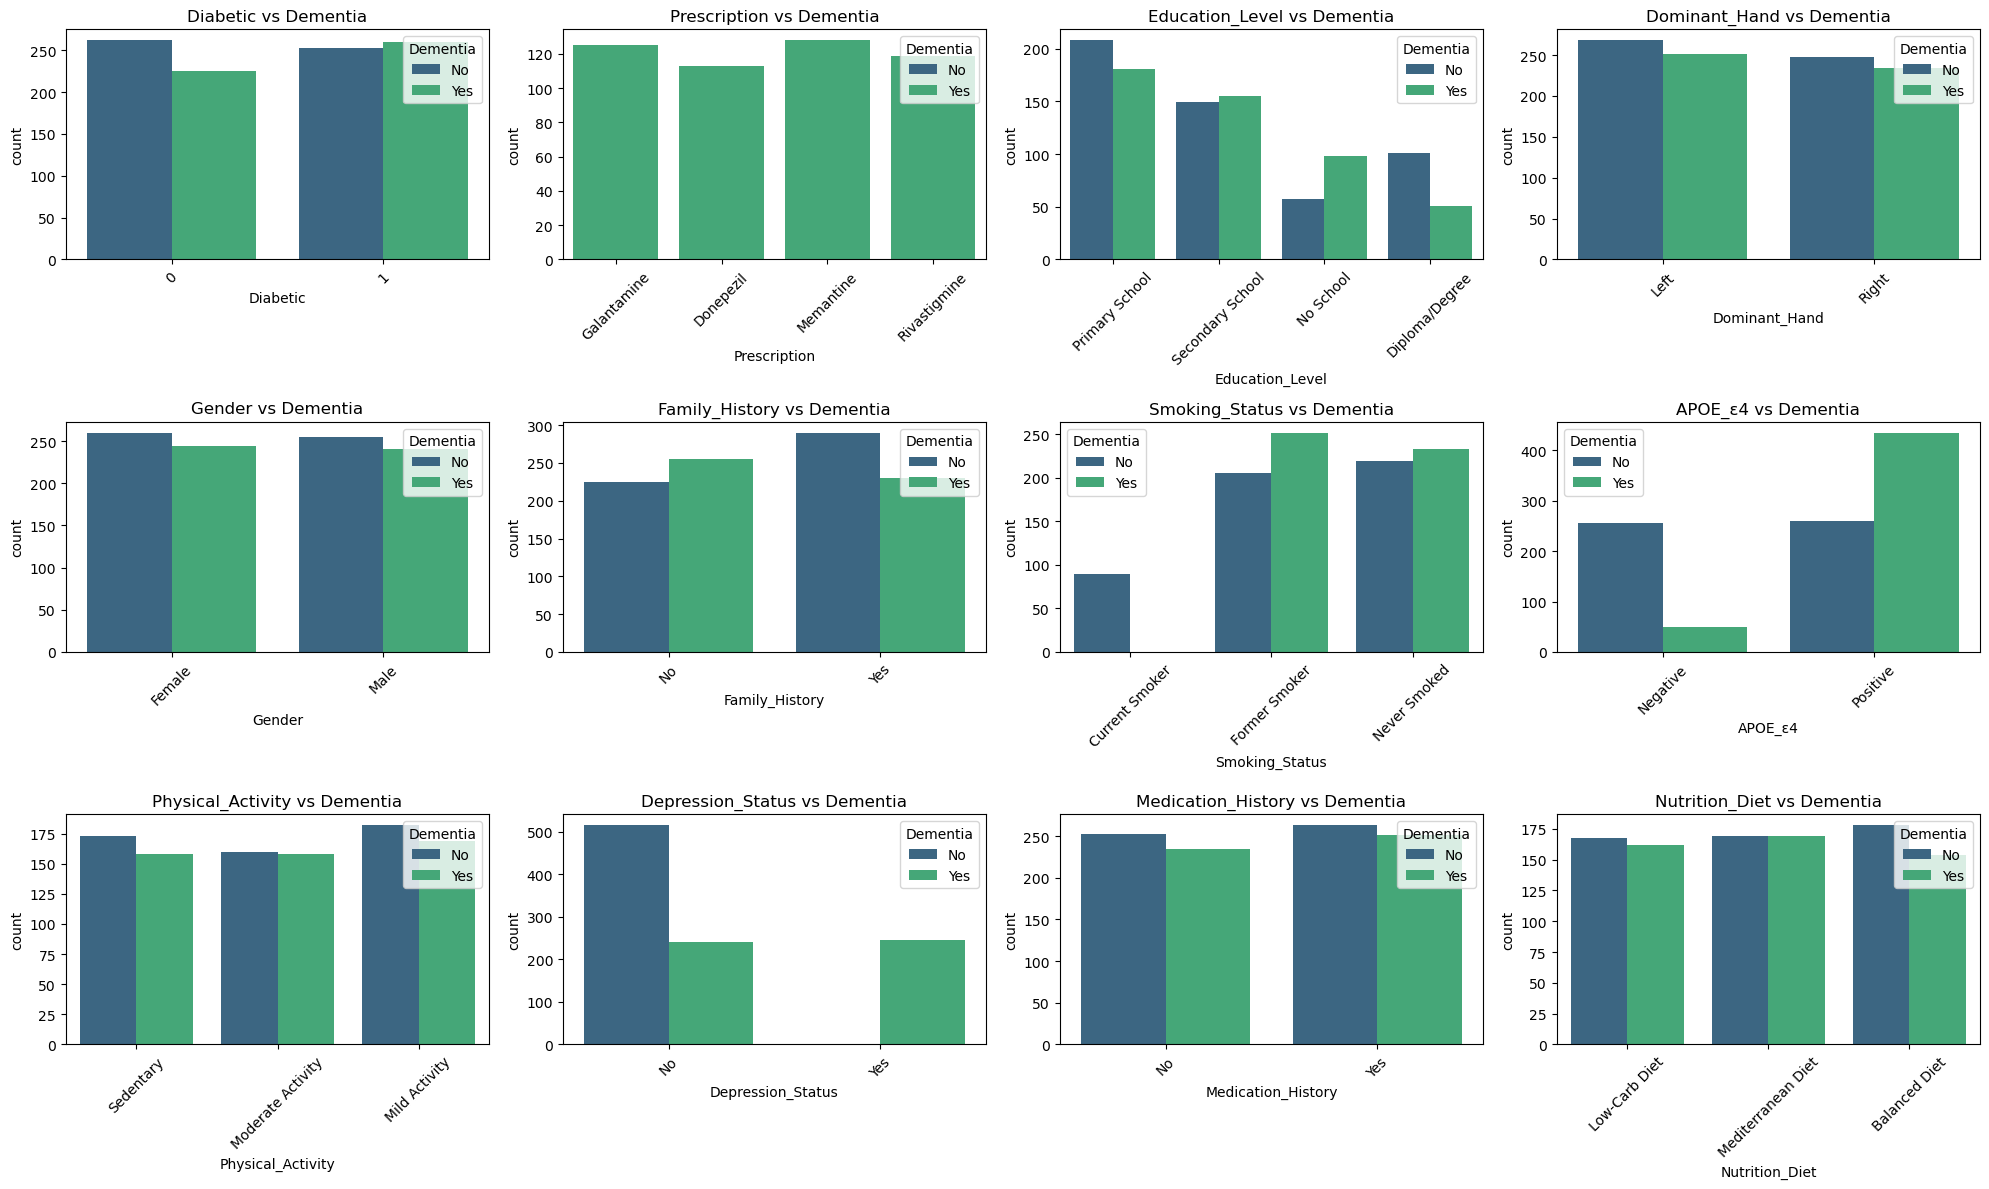

In [22]:
# Relationship between categorical features and Dementia
def plot_categorical_vs_target(df, categorical_cols, target='Dementia', rows=3, cols=4):
    fig, axes = plt.subplots(rows, cols, figsize=(20, 12))
    axes = axes.flatten()
    
    for i, feature in enumerate(categorical_cols):
        if i < len(axes):
            sns.countplot(data=df, x=feature, hue=target, ax=axes[i], palette='viridis')
            axes[i].set_title(f'{feature} vs {target}')
            axes[i].tick_params(axis='x', rotation=45)
            axes[i].legend(title=target, labels=['No', 'Yes'])
    
    for j in range(i+1, len(axes)):
        fig.delaxes(axes[j])
    
    plt.tight_layout()
    plt.show()

plot_categorical_vs_target(df, cat_cols)

### 2.3 Bivariate Analysis - Numerical vs Target  

/var/folders/d1/fzn8x7ss3597j38z1g8kc8wm0000gn/T/ipykernel_59556/1785954339.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=target, y=feature, ax=axes[i], palette='Set1')
/var/folders/d1/fzn8x7ss3597j38z1g8kc8wm0000gn/T/ipykernel_59556/1785954339.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(['No', 'Yes'])
/var/folders/d1/fzn8x7ss3597j38z1g8kc8wm0000gn/T/ipykernel_59556/1785954339.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=target, y=feature, ax=axes[i], palette='Set1')
/var/folders/d1/fzn8x7ss3597j38z1g8kc8wm0000gn/T/ipykernel_59556/178595433

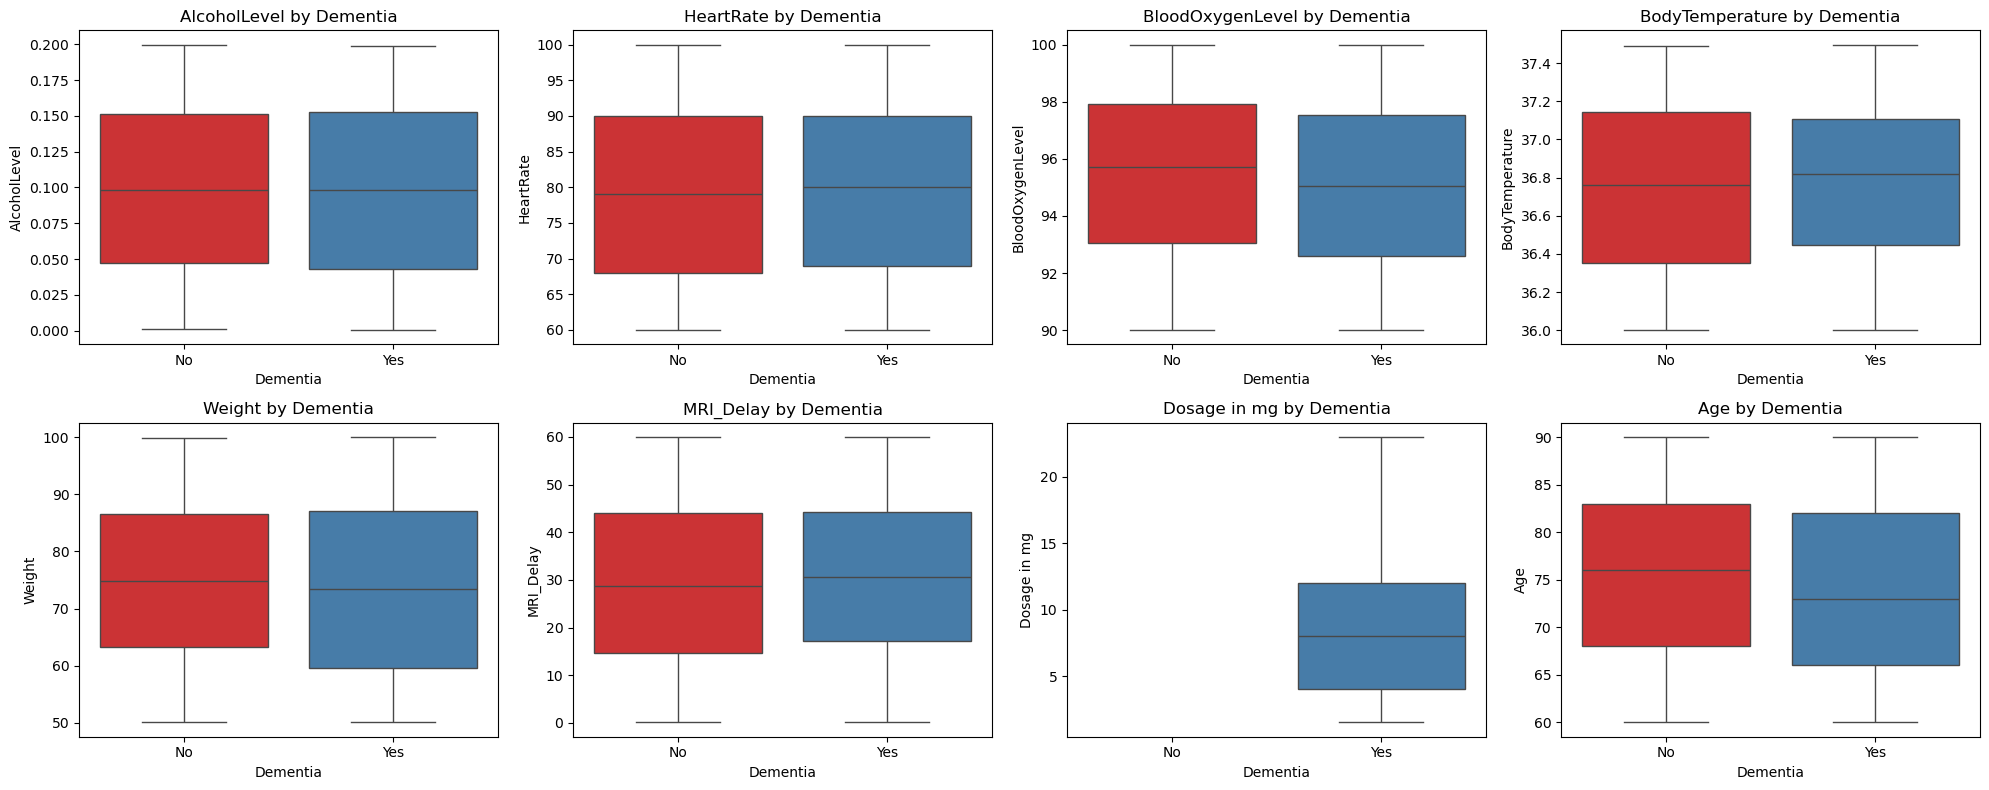

In [24]:
# Relationship between numerical features and Dementia
def plot_numerical_vs_target(df, numeric_cols, target='Dementia', rows=2, cols=4):
    fig, axes = plt.subplots(rows, cols, figsize=(20, 8))
    axes = axes.flatten()
    
    for i, feature in enumerate(numeric_cols):
        if i < len(axes):
            sns.boxplot(data=df, x=target, y=feature, ax=axes[i], palette='Set1')
            axes[i].set_title(f'{feature} by {target}')
            axes[i].set_xticklabels(['No', 'Yes'])
    
    for j in range(i+1, len(axes)):
        fig.delaxes(axes[j])
    
    plt.tight_layout()
    plt.show()

plot_numerical_vs_target(df, numeric_cols)

### Dosage, as a standalone numerical variable, is strongly correlated with Prescription and does not carry independent meaning. Prescription may indicate underlying diseases, so using it to predict disease carries a risk of data leakage. Therefore, it is dropped.

In [26]:

# Drop columns with extremely high missingness (example: Prescription and Dosage in mg)
cols_to_drop = [col for col in ['Prescription', 'Dosage in mg'] if col in df.columns]
df = df.drop(columns=cols_to_drop)
# Numerical features
numeric_features = df.select_dtypes(include=[np.number])
print("Numerical Features:")
print(numeric_features.columns.tolist())

# Categorical features
categorical_features = df.select_dtypes(include=['object', 'category'])
print("\nCategorical Features:")
print(categorical_features.columns.tolist())

Numerical Features:
['AlcoholLevel', 'HeartRate', 'BloodOxygenLevel', 'BodyTemperature', 'Weight', 'MRI_Delay', 'Age', 'Cognitive_Test_Scores']

Categorical Features:
['Diabetic', 'Education_Level', 'Dominant_Hand', 'Gender', 'Family_History', 'Smoking_Status', 'APOE_ε4', 'Physical_Activity', 'Depression_Status', 'Medication_History', 'Nutrition_Diet', 'Sleep_Quality', 'Chronic_Health_Conditions', 'Dementia']


### 2.4 Correlation Analysis
## 2.41 pointbiserialr analysis for numeric features

In [28]:
from scipy.stats import pointbiserialr

def significance_stars(p):
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return ""

numeric_cols = [col for col in numeric_cols if col in df.columns]

# --- Point-Biserial ---
corr_list = []
p_list = []
stars_corr = []

for col in numeric_cols:
    corr, p = pointbiserialr(df['Dementia'].cat.codes, df[col])
    corr_list.append(corr)
    p_list.append(p)
    stars_corr.append(significance_stars(p))

corr_df = pd.DataFrame({
    "Feature": numeric_cols,
    "Correlation": corr_list,
    "p-value": [f"{p:.4f}" for p in p_list],
    "Significance": stars_corr
})

corr_df = corr_df.reindex(corr_df['Correlation'].abs().sort_values(ascending=False).index)


display(corr_df)


,Feature,Correlation,p-value,Significance
7,Cognitive_Test_Scores,-0.843247,0.0000,***
2,BloodOxygenLevel,-0.071454,0.0238,*
6,Age,-0.062154,0.0494,*
4,Weight,-0.049563,0.1173,
3,BodyTemperature,0.033928,0.2838,
5,MRI_Delay,0.031251,0.3235,
1,HeartRate,0.012276,0.6982,
0,AlcoholLevel,-0.003720,0.9065,


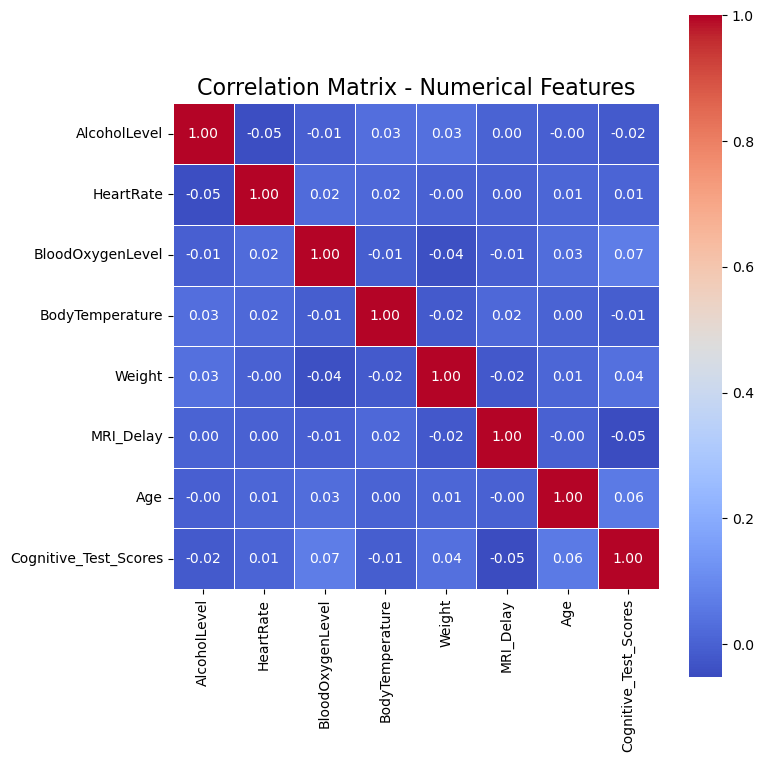

In [29]:
# Correlation heatmap for numerical features
plt.figure(figsize=(8, 8))
correlation_matrix = df[numeric_features.columns].corr()
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', 
            square=True, linewidths=0.5)
plt.title('Correlation Matrix - Numerical Features', fontsize=16)
plt.tight_layout()
plt.show()



## 2.42 chi-square analysis for catigorial features 

In [31]:

def significance_stars(p):
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return ""

categorical_cols = df.select_dtypes(include=['object', 'category']).columns
X_cat = pd.get_dummies(df[categorical_cols], drop_first=True)

chi_list = []
chi_p = []
chi_sig = []

for col in X_cat.columns:
    contingency = pd.crosstab(X_cat[col], df['Dementia'])
    chi, p, dof, ex = chi2_contingency(contingency)
    chi_list.append(chi)
    chi_p.append(f"{p:.4f}")
    chi_sig.append(significance_stars(p))

categorical_df = pd.DataFrame({
    "Feature": X_cat.columns,
    "Chi2": chi_list,
    "Chi2_pvalue": chi_p,
    "Chi2_sig": chi_sig,
    })


# order by Chi2

categorical_df = categorical_df.sort_values("Chi2", ascending=False)

display(categorical_df)


,Feature,Chi2,Chi2_pvalue,Chi2_sig
19,Dementia_1,996.000404,0.0000,***
12,Depression_Status_Yes,341.850157,0.0000,***
9,APOE_ε4_Positive,180.727498,0.0000,***
1,Education_Level_No School,15.235109,0.0001,***
7,Smoking_Status_Former Smoker,13.912147,0.0002,***
6,Family_History_Yes,7.553112,0.0060,**
17,Chronic_Health_Conditions_Heart Disease,2.861308,0.0907,
8,Smoking_Status_Never Smoked,2.850547,0.0913,
0,Diabetic_1,1.833016,0.1758,
3,Education_Level_Secondary School,0.943143,0.3315,


## 3. Preprocessing


## 3.1 Encoding - Mixed Approach
Dementia-specific encoding strategy:

Binary variables (≤2 categories): Label Encoding  
Multi-class variables (>2 categories): One-Hot Encoding  
Ordinal variables: Manual mapping (Education, Sleep Quality)  

In [34]:
from sklearn.preprocessing import LabelEncoder

# Create a copy for encoding
df_encoded = df.copy()

# Manual ordinal encoding for Education Level
education_mapping = {
    
    'No School': 1,
    'Primary School':2,
    'Secondary School': 3,
    'Diploma/Degree': 4
}
df_encoded['Education_Level'] = df_encoded['Education_Level'].map(education_mapping)

# Manual ordinal encoding for Sleep Quality
sleep_mapping = {
    'Poor': 1,
    'Good': 2
    }
df_encoded['Sleep_Quality'] = df_encoded['Sleep_Quality'].map(sleep_mapping)

# Manual ordinal encoding for Physical Activity
activity_mapping = {
    'Sedentary': 1,
    'Mild Activity': 2,
    'Moderate Activity': 3
}
df_encoded['Physical_Activity'] = df_encoded['Physical_Activity'].map(activity_mapping)

# Label Encoding for binary variables
le = LabelEncoder()
binary_cols = ['Gender', 'Family_History', 'APOE_ε4', 'Depression_Status', 
               'Medication_History', 'Dominant_Hand']

for col in binary_cols:
    if col in df_encoded.columns:
        df_encoded[col] = le.fit_transform(df_encoded[col])

# One-Hot Encoding for remaining categorical variables
onehot_cols = ['Smoking_Status', 'Nutrition_Diet', 'Chronic_Health_Conditions']

for col in onehot_cols:
    if col in df_encoded.columns:
        dummy_cols = pd.get_dummies(df_encoded[col], prefix=col, drop_first=True)
        df_encoded = pd.concat([df_encoded, dummy_cols], axis=1)
        df_encoded.drop(col, axis=1, inplace=True)



print("Encoding complete!")
print(f"Original features: {df.shape[1]-1}")
print(f"Encoded features: {df_encoded.shape[1]-2}")
print("\nEncoded dataset shape:", df_encoded.shape)
df_encoded.head()


Encoding complete!
Original features: 21
Encoded features: 23

Encoded dataset shape: (1000, 25)


,Diabetic,AlcoholLevel,HeartRate,BloodOxygenLevel,BodyTemperature,Weight,MRI_Delay,Age,Education_Level,Dominant_Hand,...,Cognitive_Test_Scores,Medication_History,Sleep_Quality,Dementia,Smoking_Status_Former Smoker,Smoking_Status_Never Smoked,Nutrition_Diet_Low-Carb Diet,Nutrition_Diet_Mediterranean Diet,Chronic_Health_Conditions_Heart Disease,Chronic_Health_Conditions_Hypertension
0,1,0.084974,98,96.230743,36.224852,57.563978,36.421028,60,2,0,...,10,0,1,0,False,False,True,False,False,False
1,0,0.016973,78,93.032122,36.183874,56.832335,31.157633,61,3,1,...,1,1,1,1,True,False,True,False,True,False
2,0,0.009000,89,93.566504,37.326321,59.759066,37.640435,69,2,1,...,8,0,1,0,True,False,False,True,True,False
3,0,0.086437,60,93.906510,37.030620,58.266471,50.673992,78,3,0,...,5,1,1,1,False,True,False,False,False,True
4,1,0.150747,67,97.508994,36.062121,67.705027,27.810601,77,3,1,...,0,1,2,1,False,True,True,False,False,False


## 3.2 Train-Test Split

In [36]:
# Separate features and target
X = df_encoded.drop(['Dementia','Cognitive_Test_Scores'], axis=1)
y = df_encoded['Dementia']

# Stratified split (important for imbalanced data)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y  # Maintain class distribution
)

print(f"Training set: {X_train.shape}")
print(f"Test set: {X_test.shape}")
print(f"\nTraining set class distribution:")
print(y_train.value_counts(normalize=True))
print(f"\nTest set class distribution:")
print(y_test.value_counts(normalize=True))

Training set: (800, 23)
Test set: (200, 23)

Training set class distribution:
Dementia
0    0.515
1    0.485
Name: proportion, dtype: float64

Test set class distribution:
Dementia
0    0.515
1    0.485
Name: proportion, dtype: float64


### 3.3 Feature Scaling



In [38]:
# 1. 标准化
scaler = StandardScaler()
X_train_scaled_array = scaler.fit_transform(X_train)
X_test_scaled_array = scaler.transform(X_test)

# 2. 转回 DataFrame，保留原列名
X_train_scaled = pd.DataFrame(X_train_scaled_array, columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled_array, columns=X_test.columns, index=X_test.index)

print("Feature scaling complete!")
print(f"Mean of scaled training features: {X_train_scaled.mean().mean():.4f}")
print(f"Std of scaled training features: {X_train_scaled.std().mean():.4f}")


Feature scaling complete!
Mean of scaled training features: -0.0000
Std of scaled training features: 1.0006


In [39]:
# Standardize features (important for distance-based algorithms)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling complete!")
print(f"Mean of scaled training features: {X_train_scaled.mean():.4f}")
print(f"Std of scaled training features: {X_train_scaled.std():.4f}")

Feature scaling complete!
Mean of scaled training features: -0.0000
Std of scaled training features: 1.0000


### 3.4 K-Fold Cross-Validation Setup

In [41]:
# 10-Fold Cross-Validation
from sklearn.model_selection import StratifiedKFold
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)


## 4. Model Training
We will set Logistic Regression served as the baseline，train and compare 6 machine learning algorithms:

Decision Tree - Interpretable, handles non-linearity
Random Forest - Ensemble method, reduces overfitting
AdaBoost - Boosting algorithm, focuses on hard samples
Gradient Boosting (XGBoost) - State-of-the-art performance
svc - Instance-based learning
neural network

Evaluation Metrics (Priority for Dementia Screening):

Recall (Sensitivity) ⭐⭐⭐ - Most important (minimize false negatives)
ROC-AUC ⭐⭐⭐ - Overall discrimination ability
Precision ⭐⭐ - Minimize false positives
F1-Score ⭐⭐ - Balance between precision and recall
Accuracy ⭐ - Overall correctness

### 4.1  Logistic Regression served as the baseline

In [44]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, roc_auc_score

# -----------------------------
# 1. Define Logistic Regression model and parameter grid
# -----------------------------
lr = LogisticRegression(solver='liblinear', class_weight='balanced', random_state=42)

lr_params = {
    'C': [0.01, 0.1, 1, 10],  # Regularization strength
    'penalty': ['l1', 'l2']   # L1 for sparsity, L2 for ridge
}

# -----------------------------
# 2. GridSearchCV with stratified CV, optimizing recall
# -----------------------------
lr_grid = GridSearchCV(
    estimator=lr,
    param_grid=lr_params,
    cv=cv,                  # previously defined 10-fold StratifiedKFold
    scoring='recall',       # prioritize sensitivity
    n_jobs=-1,
    verbose=1
)

# -----------------------------
# 3. Fit model
# -----------------------------
print("Training Logistic Regression (baseline)...")
lr_grid.fit(X_train_scaled, y_train)

# -----------------------------
# 4. Best hyperparameters & CV score
# -----------------------------
print("\nBest Logistic Regression Params:", lr_grid.best_params_)
y_pred_lr = lr_grid.predict(X_test_scaled)
y_pred_prob_lr = lr_grid.predict_proba(X_test_scaled)[:, 1]


print("\nLOGISTIC REGRESSION - TEST SET RESULTS")
print(classification_report(y_test, y_pred_lr, target_names=['No Dementia', 'Dementia']))
print("Test ROC-AUC: {:.4f}".format(roc_auc_score(y_test, y_pred_prob_lr)))




Training Logistic Regression (baseline)...
Fitting 10 folds for each of 8 candidates, totalling 80 fits

Best Logistic Regression Params: {'C': 10, 'penalty': 'l1'}

LOGISTIC REGRESSION - TEST SET RESULTS
              precision    recall  f1-score   support

 No Dementia       0.75      0.73      0.74       103
    Dementia       0.72      0.74      0.73        97

    accuracy                           0.73       200
   macro avg       0.73      0.74      0.73       200
weighted avg       0.74      0.73      0.74       200

Test ROC-AUC: 0.8512


### 4.2 Decision Tree

In [46]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report

# -----------------------------
# 1. Define model & parameter grid
# -----------------------------
dt_params = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [5, 10, 15, 20, None],
    'min_samples_split': [2, 5, 10],
    'random_state': [42]
}

# -----------------------------
# 2. GridSearchCV setup
# -----------------------------
dt_grid = GridSearchCV(
    estimator=DecisionTreeClassifier(),
    param_grid=dt_params,
    cv=cv,                  # your KFold / StratifiedKFold
    scoring='recall',       # recall for medical task
    n_jobs=-1,
    verbose=1
)

# -----------------------------
# 3. Fit model
# -----------------------------
print("Training Decision Tree...")
dt_grid.fit(X_train_scaled, y_train)

# -----------------------------
# 4. Best results from CV
# -----------------------------
print("\nBest Parameters:", dt_grid.best_params_)
print(f"Best CV Recall: {dt_grid.best_score_:.4f}")

# -----------------------------
# 5. Test set evaluation
# -----------------------------
y_pred_dt = dt_grid.predict(X_test_scaled)
y_prob_dt = dt_grid.predict_proba(X_test_scaled)[:, 1] 
auc_dt = roc_auc_score(y_test, y_prob_dt)

print("\n" + "="*60)
print("DECISION TREE - TEST SET RESULTS")
print("="*60)
print(classification_report(
    y_test, y_pred_dt,
    target_names=['No Dementia', 'Dementia']
))

print(f"Decision Tree Test ROC-AUC: {auc_dt:.4f}")

Training Decision Tree...
Fitting 10 folds for each of 30 candidates, totalling 300 fits

Best Parameters: {'criterion': 'entropy', 'max_depth': 15, 'min_samples_split': 10, 'random_state': 42}
Best CV Recall: 0.7526

DECISION TREE - TEST SET RESULTS
              precision    recall  f1-score   support

 No Dementia       0.70      0.72      0.71       103
    Dementia       0.69      0.68      0.69        97

    accuracy                           0.70       200
   macro avg       0.70      0.70      0.70       200
weighted avg       0.70      0.70      0.70       200

Decision Tree Test ROC-AUC: 0.7249


### 4.3 Random Forest

In [48]:


# -----------------------------
# Random Forest
# -----------------------------
rf_params = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5],
    'class_weight': ['balanced'],   
    'random_state': [42]
}

rf_grid = GridSearchCV(
    RandomForestClassifier(),
    rf_params,
    cv=cv,
    scoring='recall',
    n_jobs=-1,
    verbose=1
)

print("Training Random Forest...")
rf_grid.fit(X_train_scaled, y_train)

print("\nBest RF Params:", rf_grid.best_params_)
print("Best CV Recall: {:.4f}".format(rf_grid.best_score_))

y_pred_rf = rf_grid.predict(X_test_scaled)

print("\nRandom Forest Test Results:")
print(classification_report(y_test, y_pred_rf, target_names=['No Dementia','Dementia']))


Training Random Forest...
Fitting 10 folds for each of 12 candidates, totalling 120 fits

Best RF Params: {'class_weight': 'balanced', 'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 100, 'random_state': 42}
Best CV Recall: 0.6984

Random Forest Test Results:
              precision    recall  f1-score   support

 No Dementia       0.68      0.86      0.76       103
    Dementia       0.80      0.57      0.66        97

    accuracy                           0.72       200
   macro avg       0.74      0.72      0.71       200
weighted avg       0.74      0.72      0.71       200



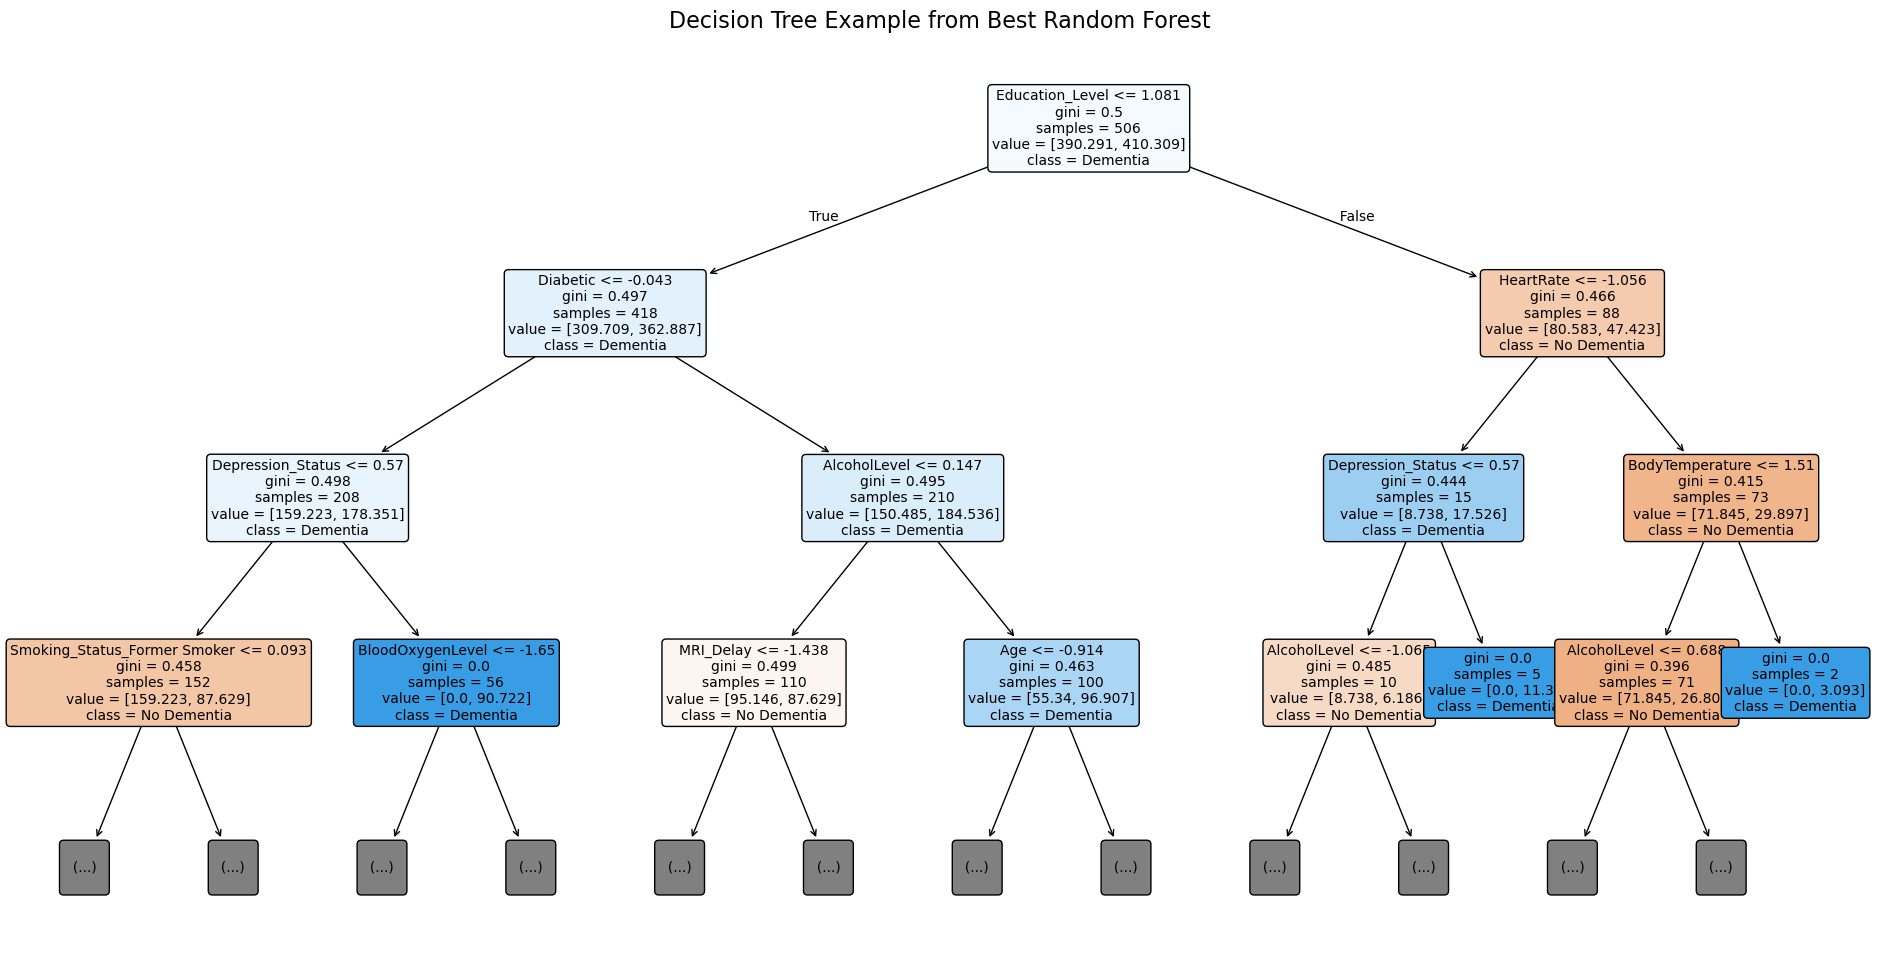

In [49]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# plot the best tree
best_rf = rf_grid.best_estimator_
one_tree = best_rf.estimators_[0]

plt.figure(figsize=(24, 12))

plot_tree(
    one_tree,
    feature_names=X_train.columns,
    class_names=['No Dementia', 'Dementia'],
    filled=True,
    rounded=True,
    fontsize=10,
    max_depth=3  # set Max depth for better visualization
)

plt.title("Decision Tree Example from Best Random Forest", fontsize=16)
plt.savefig("decision_tree_example.png", dpi=300, bbox_inches='tight')
plt.show()


In [50]:
### 4.4 AdaBoost

In [51]:
from sklearn.ensemble import AdaBoostClassifier

ada_params = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.5, 1.0, 1.5],
    'random_state': [42]
}

ada_grid = GridSearchCV(
    AdaBoostClassifier(),
    ada_params,
    cv=cv,
    scoring='recall',
    n_jobs=-1,
    verbose=1
)

print("Training AdaBoost...")
ada_grid.fit(X_train_scaled, y_train)

print("\nBest Ada Params:", ada_grid.best_params_)
print("Best CV Recall: {:.4f}".format(ada_grid.best_score_))

y_pred_ada = ada_grid.predict(X_test_scaled)

print("\nAdaBoost Test Results:")
print(classification_report(y_test, y_pred_ada, target_names=['No Dementia','Dementia']))


Training AdaBoost...
Fitting 10 folds for each of 9 candidates, totalling 90 fits


/opt/anaconda3/lib/python3.12/site-packages/sklearn/ensemble/_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/ensemble/_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/ensemble/_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/ensemble/_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(
/opt/ana


Best Ada Params: {'learning_rate': 0.5, 'n_estimators': 200, 'random_state': 42}
Best CV Recall: 0.7474

AdaBoost Test Results:
              precision    recall  f1-score   support

 No Dementia       0.75      0.79      0.77       103
    Dementia       0.76      0.72      0.74        97

    accuracy                           0.76       200
   macro avg       0.76      0.75      0.75       200
weighted avg       0.76      0.76      0.75       200



### 3.5 Gradient Boosting (XGBoost)

In [53]:
from sklearn.ensemble import GradientBoostingClassifier

gb_params = {
    'n_estimators': [100, 200],
    'learning_rate': [0.05, 0.1, 0.2],
    'max_depth': [2, 3, 4],
    'random_state': [42]
}

gb_grid = GridSearchCV(
    GradientBoostingClassifier(),
    gb_params,
    cv=cv,
    scoring='recall',
    n_jobs=-1,
    verbose=1
)

print("Training Gradient Boosting...")
gb_grid.fit(X_train_scaled, y_train)

print("\nBest GB Params:", gb_grid.best_params_)
print("Best CV Recall: {:.4f}".format(gb_grid.best_score_))

y_pred_gb = gb_grid.predict(X_test_scaled)

print("\nGradient Boosting Test Results:")
print(classification_report(y_test, y_pred_gb, target_names=['No Dementia','Dementia']))


Training Gradient Boosting...
Fitting 10 folds for each of 18 candidates, totalling 180 fits

Best GB Params: {'learning_rate': 0.2, 'max_depth': 3, 'n_estimators': 200, 'random_state': 42}
Best CV Recall: 0.7397

Gradient Boosting Test Results:
              precision    recall  f1-score   support

 No Dementia       0.70      0.73      0.71       103
    Dementia       0.70      0.67      0.68        97

    accuracy                           0.70       200
   macro avg       0.70      0.70      0.70       200
weighted avg       0.70      0.70      0.70       200



### 3.6 Support Vector Machine (SVC)

In [55]:
from sklearn.svm import SVC

svc_params = {
    'C': [0.1, 1, 10],
    'kernel': ['rbf', 'linear'],
    'gamma': ['scale', 'auto'],
    'class_weight': ['balanced']
}

svc_grid = GridSearchCV(
    SVC(),
    svc_params,
    cv=cv,
    scoring='recall',
    n_jobs=-1,
    verbose=1
)

print("Training SVC...")
svc_grid.fit(X_train_scaled, y_train)

print("\nBest SVC Params:", svc_grid.best_params_)
print("Best CV Recall: {:.4f}".format(svc_grid.best_score_))

y_pred_svc = svc_grid.predict(X_test_scaled)

print("\nSVC Test Results:")
print(classification_report(y_test, y_pred_svc, target_names=['No Dementia','Dementia']))


Training SVC...
Fitting 10 folds for each of 12 candidates, totalling 120 fits

Best SVC Params: {'C': 10, 'class_weight': 'balanced', 'gamma': 'scale', 'kernel': 'linear'}
Best CV Recall: 0.7682

SVC Test Results:
              precision    recall  f1-score   support

 No Dementia       0.75      0.75      0.75       103
    Dementia       0.73      0.73      0.73        97

    accuracy                           0.74       200
   macro avg       0.74      0.74      0.74       200
weighted avg       0.74      0.74      0.74       200



### 3.7 Neural Network 

In [57]:
from sklearn.neural_network import MLPClassifier

mlp_params = {
    'hidden_layer_sizes': [(64,), (128,), (64,32)],
    'activation': ['relu', 'tanh'],
    'learning_rate_init': [0.001, 0.01],
    'max_iter': [300],
}

mlp_grid = GridSearchCV(
    MLPClassifier(random_state=42),
    mlp_params,
    cv=cv,
    scoring='recall',
    n_jobs=-1,
    verbose=1
)

print("Training Neural Network (MLP)...")
mlp_grid.fit(X_train_scaled, y_train)

print("\nBest MLP Params:", mlp_grid.best_params_)
print("Best CV Recall: {:.4f}".format(mlp_grid.best_score_))

y_pred_mlp = mlp_grid.predict(X_test_scaled)

print("\nNeural Network Test Results:")
print(classification_report(y_test, y_pred_mlp, target_names=['No Dementia','Dementia']))


Training Neural Network (MLP)...
Fitting 10 folds for each of 12 candidates, totalling 120 fits


/opt/anaconda3/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/neural_network/_


Best MLP Params: {'activation': 'relu', 'hidden_layer_sizes': (128,), 'learning_rate_init': 0.01, 'max_iter': 300}
Best CV Recall: 0.7655

Neural Network Test Results:
              precision    recall  f1-score   support

 No Dementia       0.73      0.78      0.75       103
    Dementia       0.75      0.70      0.72        97

    accuracy                           0.74       200
   macro avg       0.74      0.74      0.74       200
weighted avg       0.74      0.74      0.74       200



## 4. Model Comparison
### 4.1 Performance Summary Table

In [59]:
import pandas as pd
from sklearn.metrics import accuracy_score, recall_score, f1_score, roc_auc_score
import matplotlib.pyplot as plt

# -----------------------------
# Model dictionary including all best models
# -----------------------------
# Add the Logistic Regression baseline to your models
models = {
    "Decision Tree": dt_grid.best_estimator_,
    "Random Forest": rf_grid.best_estimator_,
    "AdaBoost": ada_grid.best_estimator_,
    "Gradient Boosting": gb_grid.best_estimator_,
    "SVC": svc_grid.best_estimator_,
    "Neural Network": mlp_grid.best_estimator_,
    "Logistic Regression (Baseline)": lr_grid.best_estimator_  # baseline
}

results = []

# -----------------------------
# Evaluate each model on the test set
# -----------------------------
for name, model in models.items():
    # Predict class labels
    y_pred = model.predict(X_test_scaled)
    
    # Predict scores for AUC calculation
    # Use predict_proba if available, otherwise use decision_function
    if hasattr(model, "predict_proba"):
        y_scores = model.predict_proba(X_test_scaled)[:, 1]  # probability of positive class
    else:
        y_scores = model.decision_function(X_test_scaled)
    
    # Collect evaluation metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test, y_scores)
    })

# -----------------------------
# Convert results to DataFrame and sort by AUC
# -----------------------------
df_results = pd.DataFrame(results)
print("\n===== MODEL COMPARISON TABLE =====\n")
print(df_results.sort_values("AUC", ascending=False).reset_index(drop=True))



===== MODEL COMPARISON TABLE =====

                            Model  Accuracy    Recall  F1-score       AUC
0  Logistic Regression (Baseline)     0.735  0.742268  0.730964  0.851166
1                             SVC     0.740  0.731959  0.731959  0.845161
2                        AdaBoost     0.755  0.721649  0.740741  0.843859
3                  Neural Network     0.740  0.701031  0.723404  0.841557
4                   Random Forest     0.720  0.567010  0.662651  0.841057
5               Gradient Boosting     0.700  0.670103  0.684211  0.816435
6                   Decision Tree     0.700  0.680412  0.687500  0.724852


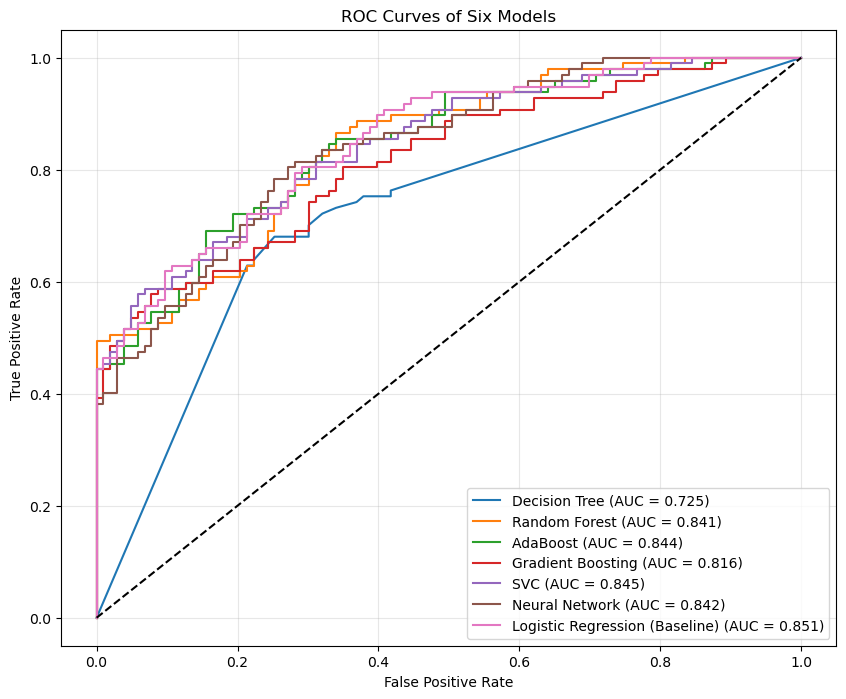

In [60]:
plt.figure(figsize=(10, 8))

for name, model in models.items():
    
    if hasattr(model, "predict_proba"):
        y_scores = model.predict_proba(X_test_scaled)[:, 1]
    else:
        y_scores = model.decision_function(X_test_scaled)
    
    fpr, tpr, _ = roc_curve(y_test, y_scores)
    auc_val = roc_auc_score(y_test, y_scores)
    
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.3f})")

# Random baseline
plt.plot([0, 1], [0, 1], 'k--')

plt.title("ROC Curves of Six Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(alpha=0.3)
plt.show()



Training Logistic Regression...


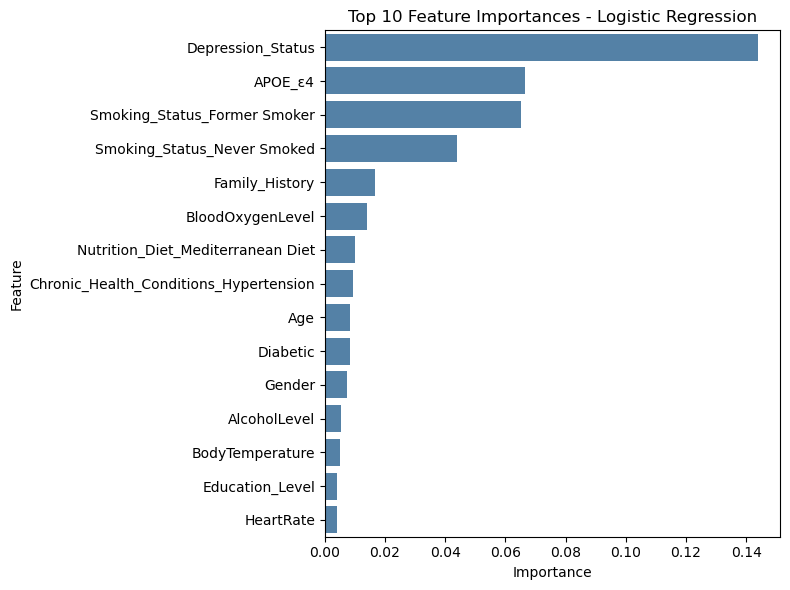


Training SVC...


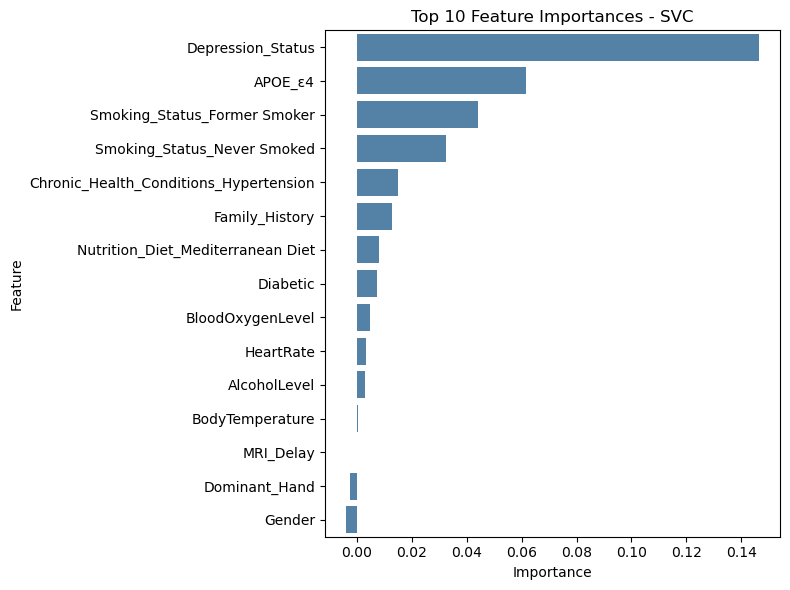


Training AdaBoost...


/opt/anaconda3/lib/python3.12/site-packages/sklearn/ensemble/_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(


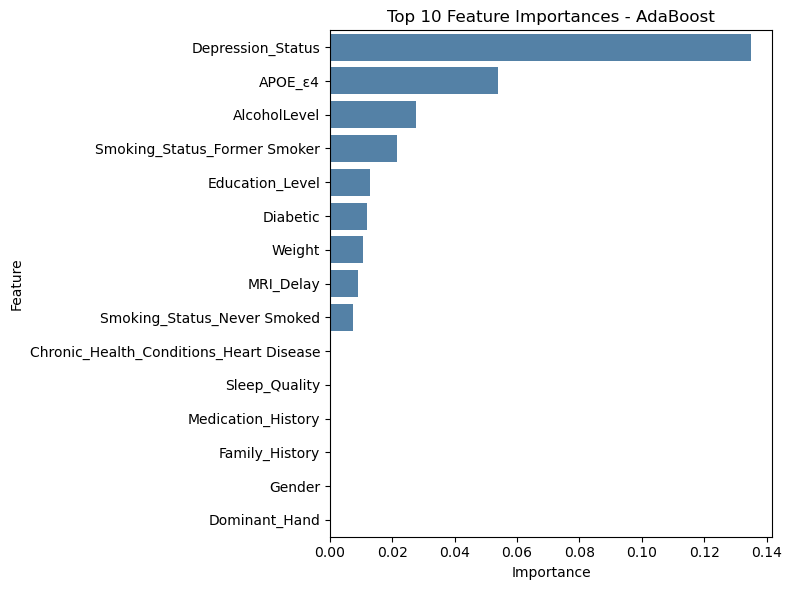

Number of unique top features: 16
Unique top features:
1. Depression_Status
2. APOE_ε4
3. Smoking_Status_Former Smoker
4. Smoking_Status_Never Smoked
5. Family_History
6. BloodOxygenLevel
7. Nutrition_Diet_Mediterranean Diet
8. Chronic_Health_Conditions_Hypertension
9. Age
10. Diabetic
11. HeartRate
12. AlcoholLevel
13. Education_Level
14. Weight
15. MRI_Delay
16. Chronic_Health_Conditions_Heart Disease

Top 5 features:
1. Depression_Status
2. APOE_ε4
3. Smoking_Status_Former Smoker
4. Smoking_Status_Never Smoked
5. Family_History


IndexError: only integers, slices (`:`), ellipsis (`...`), numpy.newaxis (`None`) and integer or boolean arrays are valid indices

In [64]:

from sklearn.inspection import permutation_importance
from sklearn.preprocessing import StandardScaler
# --- 3. Define models ---
models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'SVC': SVC(kernel='linear', probability=True, random_state=42),
    'AdaBoost': AdaBoostClassifier(random_state=42)
}

# --- 4. Train models & compute permutation importance ---
feature_importances = {}

for name, model in models.items():
    print(f"\nTraining {name}...")
    # 对 AdaBoost、Logistic、SVC 都使用 permutation importance
    if name in ['Logistic Regression', 'SVC']:
        model.fit(X_train_scaled, y_train)
        result = permutation_importance(model, X_test_scaled, y_test, n_repeats=10, random_state=42)
        importance = pd.DataFrame({
            'Feature': X.columns,
            'Importance': result.importances_mean
        }).sort_values('Importance', ascending=False)
        plot_X = X_test_scaled
    else:  # AdaBoost
        model.fit(X_train, y_train)
        result = permutation_importance(model, X_test, y_test, n_repeats=10, random_state=42)
        importance = pd.DataFrame({
            'Feature': X.columns,
            'Importance': result.importances_mean
        }).sort_values('Importance', ascending=False)
        plot_X = X_test

    feature_importances[name] = importance

    # --- Plot feature importance ---
    plt.figure(figsize=(8,6))
    sns.barplot(x='Importance', y='Feature', data=importance.head(15), color='steelblue')
    plt.title(f'Top 10 Feature Importances - {name}')
    plt.tight_layout()
    plt.show()

# --- 5. Select top features based on permutation importance ---
top_features = pd.concat([
    feature_importances['Logistic Regression'].head(10),
    feature_importances['SVC'].head(10),
    feature_importances['AdaBoost'].head(10)
])['Feature'].unique()


top_features = list(map(str, top_features))
#print("Selected top features:", top_features)
print(f"Number of unique top features: {len(top_features)}")
print("Unique top features:")
for i, f in enumerate(top_features, 1):
    print(f"{i}. {f}")

# top 5 
print("\nTop 5 features:")
for i, f in enumerate(top_features[:5], 1):
    print(f"{i}. {f}")


# --- 6. Retrain models on top features ---
X_train_top = X_train_scaled[top_features].copy()
X_test_top = X_test_scaled[top_features].copy()

for name, model in models.items():
    print(f"\nRetraining {name} with top features...")
    model.fit(X_train_top, y_train)
    y_pred = model.predict(X_test_top)
    print(classification_report(y_test, y_pred))


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import classification_report, roc_auc_score
import pandas as pd

models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'SVC': SVC(kernel='linear', probability=True, random_state=42),
    'AdaBoost': AdaBoostClassifier(random_state=42)
}


X_train_top = X_train[top_features].copy()
X_test_top = X_test[top_features].copy()


metrics_list = []


for name, model in models.items():
    model.fit(X_train_top, y_train)
    
    y_pred = model.predict(X_test_top)
    
    # 用 predict_proba 或 decision_function 计算 ROC-AUC
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test_top)[:, 1]
    else:
        y_prob = model.decision_function(X_test_top)
    
    auc = roc_auc_score(y_test, y_prob)
    
   
    report_dict = classification_report(y_test, y_pred, output_dict=True)
  
    precision = report_dict['1']['precision']
    recall = report_dict['1']['recall']
    f1 = report_dict['1']['f1-score']
    
    metrics_list.append({
        "Model": name,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "ROC-AUC": auc
    })


metrics_df = pd.DataFrame(metrics_list)
display(metrics_df)


In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(8, 6))

for name, model in models.items():
   
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test_top)[:, 1]
    else:
        y_score = model.decision_function(X_test_top)
    
    fpr, tpr, thresholds = roc_curve(y_test, y_score)
    roc_auc = auc(fpr, tpr)
    
    plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {roc_auc:.3f})')

# plot
plt.plot([0, 1], [0, 1], color='grey', lw=1, linestyle='--')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC Curves - Top Features', fontsize=14)
plt.legend(loc='lower right', fontsize=10)
plt.grid(True)
plt.tight_layout()
plt.show()


Before modeling, statistical tests such as chi-square or point-biserial correlation evaluate each feature independently. These tests measure the strength of the association between a single predictor and the target variable. After modeling, feature importance reflects how much the model actually relies on each feature when all predictors are considered together. Therefore, statistical importance and model importance may differ because features can overlap, compete, or explain shared variance.

In my dataset, Depression showed the strongest group difference between dementia and non-dementia participants (very high chi-square and extremely small p-value), whereas age showed only moderate differences. This explains why both correlation tests and model-based importance ranked Depression as the top predictor. In many published studies, age appears more important because their samples show larger age differences across diagnostic groups, or because depression is measured less reliably. Thus, differences in dataset characteristics naturally lead to different importance rankings, and my results are statistically valid for the data used.